# Spatio-Temporal EEG Transformer (ST-EEGFormer)

This notebook trains and evaluates a Spatio-Temporal EEG Transformer (ST-EEGFormer) using pretrained encoder weights and LoRA adapters to decode binocular rivalry states (Congruent vs. Incongruent Pure).

### Spatio-Temporal EEG Transformer (ST-EEGFormer) Pipeline with LoRA Adapters

This model uses a ViT-style transformer block to process spatial and temporal EEG patches. Parameter-efficient fine-tuning is implemented via LoRA (Low-Rank Adaptation) adapters injected in Attention projection layers, while keeping the base ViT weights frozen.

```mermaid
graph TD
    A[Input Epochs: batch, channels, times] --> B[Reshape to batch*channels, 1, times]
    B --> C[Temporal Patch Embedding: 1D CNN]
    C --> D[Add Spatial & Temporal Positional Embeddings]
    D --> E[Flatten channels & patches to sequence]
    E --> F[Prepend Classification Token: cls_token]
    F --> G[Transformer Encoder Blocks with LoRA adapters]
    G --> H[Extract cls_token state & LayerNorm]
    H --> I[Fully Connected Classifier Head]
    I --> J[Classification Output: Congruent vs Incongruent Pure]
```

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '4'
os.environ['MKL_NUM_THREADS'] = '4'
os.environ['OPENBLAS_NUM_THREADS'] = '4'
os.environ['VECLIB_MAXIMUM_THREADS'] = '4'
os.environ['NUMEXPR_NUM_THREADS'] = '4'
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

import sys
import warnings
import subprocess
from pathlib import Path
import matplotlib.pyplot as plt
%pip install -q mne timm safetensors huggingface_hub shap
import mne
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, precision_recall_curve, auc
from scipy.stats import ttest_1samp, wilcoxon
from mne.stats import fdr_correction

try:
    NOTEBOOK_DIR = Path(__file__).resolve().parent
except NameError:
    NOTEBOOK_DIR = Path.cwd()

IN_KAGGLE = 'KAGGLE_KERNEL_RUN_TYPE' in os.environ

if IN_KAGGLE:
    # 1. Busquem on s'ha descomprimit la carpeta 'br_analysis'
    found_src = None
    for root, dirs, files in os.walk('/kaggle/input'):
        if 'br_analysis' in dirs:
            found_src = Path(root)
            break
            
    if found_src:
        SRC_DIR = found_src
        print(f"Kaggle Dataset detectat correctament a: {SRC_DIR}")
    else:
        SRC_DIR = Path("/kaggle/input")
        print("⚠️ ALERTA: No s'ha trobat la carpeta 'br_analysis' a /kaggle/input")
        
    IN_COLAB = False
else:
    SRC_DIR = (
        Path("/content/drive/MyDrive/TFG_Nils_2026/03_Codi")
        if "google.colab" in sys.modules
        else NOTEBOOK_DIR.parent.parent / "src"
    )
    try:
        from google.colab import drive
        IN_COLAB = True
        drive.mount("/content/drive")
    except ImportError:
        IN_COLAB = False

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

# Importacions de la llibreria local br_analysis
from br_analysis import (
    BinaryTaskConfig,
    RawEpochSpec,
    detect_project_paths,
    load_raw_epoch_dataset,
    get_task_config,
    temporal_stratified_splits
)
from br_analysis.pretrained import (
    BackboneClassifier,
    prepare_lora_backbone,
    load_backbone_weights,
    align_channels_to_steegformer,
    ST_EEGFORMER_CHANNELS
)
from br_analysis.torch_training import (
    TorchTrainConfig,
    cross_validate_torch_model,
    plot_fold_metrics,
    plot_torch_history,
    build_dataloader,
    standardize_train_test,
    _evaluate
)
from br_analysis.torch_models import count_trainable_parameters

# 2. Sobreescrivim detect_project_paths per crear carpetes només a /kaggle/working
if IN_KAGGLE and found_src:
    import br_analysis.config
    from br_analysis.config import ProjectPaths
    
    def detect_project_paths_kaggle(analysis_name: str, **kwargs):
        input_project_dir = found_src / "TFG_Nils_2026"
        output_project_dir = Path("/kaggle/working/TFG_Nils_2026")
        
        paths = ProjectPaths(
            project_dir=output_project_dir,
            data_dir=input_project_dir / "02_Data" / "01_Preprocessed_epochs",
            analysis_root=input_project_dir / "04_Anàlisi",
            analysis_dir=output_project_dir / "04_Anàlisi" / analysis_name,
            cache_dir=output_project_dir / "04_Anàlisi" / analysis_name / "cache",
            tables_dir=output_project_dir / "04_Anàlisi" / analysis_name / "tables",
            figures_dir=output_project_dir / "04_Anàlisi" / analysis_name / "figures",
        )
        
        # Creem només els directoris d'escriptura (evitant errors de Read-only filesystem)
        for folder in (
            paths.analysis_dir,
            paths.cache_dir,
            paths.tables_dir,
            paths.figures_dir,
        ):
            folder.mkdir(parents=True, exist_ok=True)
            
        return paths
        
    br_analysis.config.detect_project_paths = detect_project_paths_kaggle
    detect_project_paths = detect_project_paths_kaggle
    print("S'ha configurat correctament la detecció de paths dinàmica d'escriptura.")

# 3. Configuració global de MNE, llavors de control i GPU CUDA
warnings.filterwarnings("ignore", category=RuntimeWarning)
mne.set_log_level("WARNING")

RANDOM_SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    torch.backends.cudnn.benchmark = True
    print(f"Using CUDA GPU: {torch.cuda.get_device_name(0)}")
else:
    print("CUDA is not available; using CPU.")

Note: you may need to restart the kernel to use updated packages.
CUDA is not available; using CPU.


## Task And Environment Setup

In [2]:
TASK_TAG = "c_vs_ip_steegformer"
paths = detect_project_paths("c_vs_i_steegformer", in_colab=IN_COLAB)
SELECTED_SUBJECTS_CSV = paths.analysis_root / "exploration" / "tables" / "subjectes_seleccionats.csv"
MAX_SUBJECTS = 24

REPO_DIR = paths.analysis_dir / "external" / "STEEGFormer"
WEIGHTS_DIR = paths.cache_dir / "steegformer_weights"
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
if not REPO_DIR.exists():
    REPO_DIR.parent.mkdir(parents=True, exist_ok=True)
    subprocess.run(["git", "clone", "https://github.com/LiuyinYang1101/STEEGFormer", str(REPO_DIR)], check=True)

if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))
for subdir in REPO_DIR.iterdir():
    if subdir.is_dir() and str(subdir) not in sys.path:
        sys.path.insert(0, str(subdir))

from models_mae_eeg import mae_vit_small_patch16
from huggingface_hub import hf_hub_download

checkpoint_path = Path(
    hf_hub_download(
        repo_id="eugenehp/ST-EEGFormer",
        filename="ST-EEGFormer_small_encoder.safetensors",
        local_dir=str(WEIGHTS_DIR),
        local_dir_use_symlinks=False,
    )
)

task = get_task_config("c_vs_ip", paths.analysis_root, name=TASK_TAG, analysis_window=(0.0, 1.5))

print(f"Project: {paths.project_dir}")
print(f"Data: {paths.data_dir}")
print(f"Results: {paths.analysis_dir}")
print(f"Checkpoint: {checkpoint_path}")

c:\Users\nils\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:834: UserWarning: `local_dir_use_symlinks` parameter is deprecated and will be ignored. The process to download files to a local folder has been updated and do not rely on symlinks anymore. You only need to pass a destination folder as`local_dir`.
For more details, check out https://huggingface.co/docs/huggingface_hub/main/en/guides/download#download-files-to-local-folder.
  warnings.warn(


Project: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026
Data: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\02_Data\01_Preprocessed_epochs
Results: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i_steegformer
Checkpoint: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i_steegformer\cache\steegformer_weights\ST-EEGFormer_small_encoder.safetensors


## Load Epochs And Align Channels

In [3]:
spec = RawEpochSpec(picks=None, bandpass=(1.0, 40.0), resample_sfreq=128.0)
dataset = load_raw_epoch_dataset(paths, task, spec)
X_raw = np.asarray(dataset.X, dtype=np.float32)
y = np.asarray(dataset.y, dtype=np.int64)
subjects = np.asarray(dataset.subjects, dtype=object)
SUBJECT_ID = "P057"
ch_names = list(dataset.channel_names)
times = dataset.times
sfreq = 128.0

# Use native epoch length
TARGET_LEN = X_raw.shape[-1]
X_raw = X_raw

# Align channels to standard 142 channels
X = align_channels_to_steegformer(X_raw, ch_names)

print(f"Aligned X shape: {X.shape} (trials, padded channels, times)")
print(f"Classes: {np.bincount(y)}")

Loading preprocessed dataset from cache: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\cache\dataset_c_vs_ip_subj24_bp1.0_40.0_sf128.0_win0.0_1.5_pkall.joblib
Aligned 60/60 channels to 142-channel format.
Aligned X shape: (5870, 142, 192) (trials, padded channels, times)
Classes: [2935 2935]


## ST-EEGFormer Model Definition & Configuration

In [4]:
def make_model():
    backbone = mae_vit_small_patch16()
    load_backbone_weights(backbone, checkpoint_path, strict=False)
    prepare_lora_backbone(
        backbone,
        include_substrings=("attn",),
        exclude_substrings=("head", "classifier", "decoder", "patch_embed", "tokenizer"),
        r=8,
        alpha=16.0,
        dropout=0.05,
        train_classifier=False,
    )
    model = BackboneClassifier(backbone, n_classes=2, example_input=torch.from_numpy(X[:1]))
    return model


train_cfg = TorchTrainConfig(
    epochs=50,
    batch_size=8,
    lr=2e-4,
    weight_decay=1e-4,
    patience=15,
    n_splits=5,
    val_size=0.2,
    random_seed=RANDOM_SEED,
    device=DEVICE,
    progress=True,
)

## 3. Cohort-Wide Training (LoRA Fine-tuning)

We train the LoRA fine-tuned ST-EEGFormer model across all 24 subjects individually and cache the results.

In [5]:
cohort_metrics_path = paths.tables_dir / f"cohort_cv_metrics_{TASK_TAG}.csv"
cohort_fold_metrics_path = paths.tables_dir / f"cohort_fold_metrics_{TASK_TAG}.csv"
subject_ids = pd.unique(subjects).tolist()

if cohort_metrics_path.exists() and cohort_fold_metrics_path.exists():
    print("Loading ST-EEGFormer cohort metrics from cache...")
    df_cohort = pd.read_csv(cohort_metrics_path)
    df_cohort_folds = pd.read_csv(cohort_fold_metrics_path)
else:
    print("Running ST-EEGFormer cohort-wide cross-validation with LoRA adapters...")
    cohort_results = []
    cohort_fold_results = []

    silent_cfg = TorchTrainConfig(
        epochs=train_cfg.epochs,
        batch_size=train_cfg.batch_size,
        lr=train_cfg.lr,
        weight_decay=train_cfg.weight_decay,
        patience=train_cfg.patience,
        n_splits=train_cfg.n_splits,
        val_size=train_cfg.val_size,
        random_seed=train_cfg.random_seed,
        device=train_cfg.device,
        progress=True,
    )

    for sub in subject_ids:
        subj_metrics_path = paths.cache_dir / f"metrics_{TASK_TAG}_sub{sub}.csv"
        if subj_metrics_path.exists():
            print(f"Loading cached metrics for subject {sub}...")
            steeg_metrics = pd.read_csv(subj_metrics_path)
        else:
            print(f"Training/Evaluating subject {sub}...")
            import gc

            gc.collect()
            torch.cuda.empty_cache()
            steeg_metrics, _ = cross_validate_torch_model(
                X,
                y,
                make_model,
                silent_cfg,
                subjects=subjects,
                subject_id=sub,
                save_weights_dir=paths.cache_dir,
                weights_prefix=f"{TASK_TAG}_sub{sub}",
                load_weights=True,
            )
            steeg_metrics.to_csv(subj_metrics_path, index=False)

        cohort_results.append(
            {
                "subject": sub,
                "steegformer_acc": steeg_metrics["test_acc"].mean(),
                "steegformer_auc": steeg_metrics["test_auc"].mean(),
                "steegformer_bal_acc": steeg_metrics["test_balanced_acc"].mean(),
            }
        )

        for idx, row in steeg_metrics.iterrows():
            cohort_fold_results.append(
                {
                    "subject": sub,
                    "model": "ST-EEGFormer",
                    "fold": int(row["fold"]),
                    "test_acc": row["test_acc"],
                    "test_auc": row["test_auc"],
                    "test_balanced_acc": row["test_balanced_acc"],
                }
            )

    df_cohort = pd.DataFrame(cohort_results)
    df_cohort.to_csv(cohort_metrics_path, index=False)
    df_cohort_folds = pd.DataFrame(cohort_fold_results)
    df_cohort_folds.to_csv(cohort_fold_metrics_path, index=False)
    print(f"Saved cohort metrics to: {cohort_metrics_path}")
# Global Cohort CV Summary (mean ± std)
print("\n" + "=" * 50)
print("GLOBAL COHORT CROSS-VALIDATION SUMMARY")
print("=" * 50)
for model_name in df_cohort_folds["model"].unique():
    model_df = df_cohort_folds[df_cohort_folds["model"] == model_name]
    print(f"Model: {model_name}")
    for f in sorted(model_df["fold"].unique()):
        fold_df = model_df[model_df["fold"] == f]
        mean_f = fold_df["test_acc"].mean()
        std_f = fold_df["test_acc"].std()
        print(f"  Fold {f} Accuracy: {mean_f:.4f} ± {std_f:.4f}")
    mean_cv = model_df["test_acc"].mean()
    std_cv = model_df["test_acc"].std()
    print(f"  Average CV Accuracy: {mean_cv:.4f} ± {std_cv:.4f}")
print("=" * 50 + "\n")


Loading ST-EEGFormer cohort metrics from cache...


## 3.5 Cohort-Wide Predictions Extraction

We extract model predictions across all subjects and folds once, caching them in memory so we don't have to reload models in subsequent sections.

In [ ]:
# Extract predictions across all subjects and folds
all_y_true = []
all_probs = []
subject_y_trues = {}
subject_y_probs = {}
subject_fold_predictions = {}  # {sub: {fold: (y_true, y_prob)}}

device = torch.device(DEVICE)

print("Extracting cohort predictions across all subjects and folds...")
for sub in subject_ids:
    splits = list(temporal_stratified_splits(y[subjects == sub], train_cfg.n_splits))
    X_sub = X[subjects == sub]
    y_sub = y[subjects == sub]

    sub_y_true = []
    sub_y_prob = []
    subject_fold_predictions[sub] = {}

    for fold, (train_idx, test_idx) in enumerate(splits, start=1):
        _, X_test = standardize_train_test(X_sub[train_idx], X_sub[test_idx])
        y_test = y_sub[test_idx]

        weights_path = paths.cache_dir / f"{TASK_TAG}_sub{sub}_fold{fold}.pt"
        if weights_path.exists():
            model = make_model().to(device)
            model.load_state_dict(torch.load(weights_path, map_location=device), strict=False)
            model.eval()

            loader = build_dataloader(X_test, y_test, batch_size=train_cfg.batch_size, shuffle=False, device=device)
            _, _, y_true_arr, p = _evaluate(model, loader, device)
            all_y_true.extend(y_true_arr)
            all_probs.extend(p)
            sub_y_true.extend(y_true_arr)
            sub_y_prob.extend(p)
            subject_fold_predictions[sub][fold] = (y_true_arr, p)

    if len(sub_y_true) > 0:
        subject_y_trues[sub] = np.array(sub_y_true)
        subject_y_probs[sub] = np.array(sub_y_prob)

all_y_true = np.array(all_y_true)
all_probs = np.array(all_probs)
all_preds = (all_probs >= 0.5).astype(int)


## 4. Single-Subject Detailed Performance Comparison (P057)

In [ ]:
from sklearn.metrics import classification_report, roc_curve, precision_recall_curve, auc
import matplotlib.pyplot as plt

# Extract P057-specific predictions from the cohort predictions
y_true_all = subject_y_trues[SUBJECT_ID]
probs = subject_y_probs[SUBJECT_ID]
preds = (probs >= 0.5).astype(int)

print("=== ST-EEGFormer Classification Report (Subject P057) ===")
print(classification_report(y_true_all, preds, target_names=[task.class_0, task.class_1], zero_division=0.0))

# Plot ROC/PR curves
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(11, 4.5))
fpr, tpr, _ = roc_curve(y_true_all, probs)
ax_roc.plot(fpr, tpr, label=f"ST-EEGFormer (AUC = {auc(fpr, tpr):.3f})", color="blue", linewidth=2)
ax_roc.plot([0, 1], [0, 1], "k--", alpha=0.5)
ax_roc.set_title("ROC Curve (Subject P057)")
ax_roc.set_xlabel("False Positive Rate")
ax_roc.set_ylabel("True Positive Rate")
ax_roc.legend()

prec, rec, _ = precision_recall_curve(y_true_all, probs)
ax_pr.plot(rec, prec, label=f"ST-EEGFormer (μP = {auc(rec, prec):.3f})", color="blue", linewidth=2)
ax_pr.plot([0, 1], [0.5, 0.5], "k--", alpha=0.5)
ax_pr.set_title("Precision-Recall Curve (Subject P057)")
ax_pr.set_xlabel("Recall")
ax_pr.set_ylabel("Precision")
ax_pr.legend()

plt.tight_layout()
plt.savefig(paths.figures_dir / f"roc_pr_{{TASK_TAG}}_P057.png", dpi=180, bbox_inches="tight")
plt.show()


## 5. Single-Subject Fold Analysis & Saliency Mapping (P057)

We statistically evaluate the 5 CV folds against the 50% chance level and extract absolute gradients to map spatial and temporal importances.

=== P057 Fold Accuracies ===
Accuracies: [0.6   0.475 0.625 0.875 0.75 ]
One-sample t-test (vs 0.5): t-statistic = 2.416, p-value = 0.0730
One-sample Wilcoxon (vs 0.5): W-statistic = 1.000, p-value = 0.1250


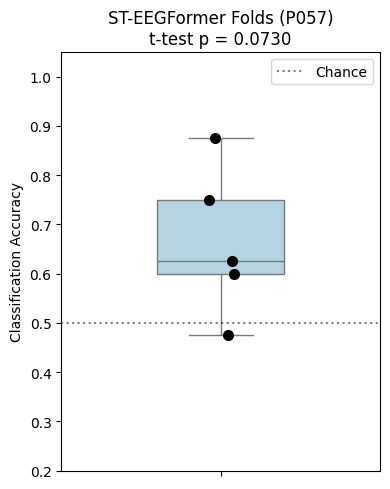

In [7]:
metrics_sub = df_cohort_folds[df_cohort_folds["subject"] == SUBJECT_ID].copy()
acc_folds = metrics_sub["test_acc"].values

t_stat, p_val_t = ttest_1samp(acc_folds, 0.5)
w_stat, p_val_w = wilcoxon(acc_folds - 0.5)

print("=== P057 Fold Accuracies ===")
print(f"Accuracies: {acc_folds}")
print(f"One-sample t-test (vs 0.5): t-statistic = {t_stat:.3f}, p-value = {p_val_t:.4f}")
print(f"One-sample Wilcoxon (vs 0.5): W-statistic = {w_stat:.3f}, p-value = {p_val_w:.4f}")

plt.figure(figsize=(4, 5))
sns.boxplot(y=acc_folds, color="lightblue", width=0.4)
sns.stripplot(y=acc_folds, color="black", size=8, jitter=0.05)
plt.axhline(0.5, color="black", linestyle=":", alpha=0.5, label="Chance")
plt.title(f"ST-EEGFormer Folds (P057)\nt-test p = {p_val_t:.4f}")
plt.ylabel("Classification Accuracy")
plt.ylim(0.2, 1.05)
plt.legend()
plt.tight_layout()
plt.savefig(paths.figures_dir / f"fold_accuracy_boxplot_P057_{TASK_TAG}.png", dpi=180, bbox_inches="tight")
plt.show()

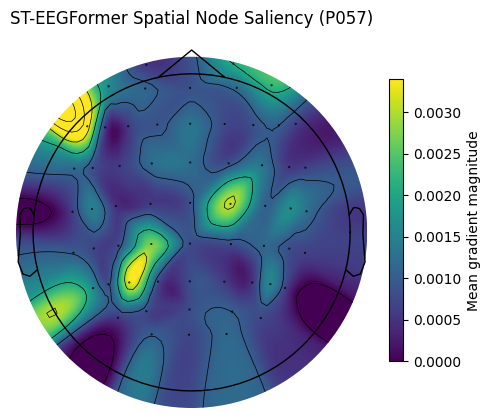

C:\Users\nils\AppData\Local\Temp\ipykernel_8080\2449130334.py:67: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


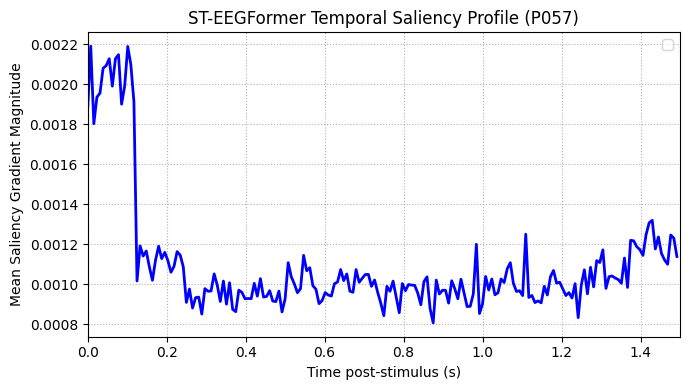

In [8]:
# Compute P057 Channel/Temporal Saliency (gradients w.r.t input channels/time)
device = torch.device(DEVICE)
splits = list(temporal_stratified_splits(y[subjects == SUBJECT_ID], train_cfg.n_splits))
X_sub = X[subjects == SUBJECT_ID]
y_sub = y[subjects == SUBJECT_ID]

# Build index mapping from 142 channels to original 60 channels
target_index_by_name = {name.upper(): idx for idx, name in enumerate(ST_EEGFORMER_CHANNELS)}
original_indices_in_142 = [target_index_by_name[ch.upper()] for ch in ch_names]

saliencies = []
for fold, (train_idx, test_idx) in enumerate(splits, start=1):
    _, X_test = standardize_train_test(X_sub[train_idx], X_sub[test_idx])
    y_test = y_sub[test_idx]

    # Filter conflict trials (IP)
    idx_c1 = y_test == 1
    if not np.any(idx_c1):
        continue

    model = make_model().to(device)
    model.load_state_dict(
        torch.load(paths.cache_dir / f"{TASK_TAG}_sub{SUBJECT_ID}_fold{fold}.pt", map_location=device), strict=False
    )
    model.eval()

    X_tensor = torch.from_numpy(X_test[idx_c1]).to(device)
    X_tensor.requires_grad_()
    logits = model(X_tensor)
    probs_out = torch.softmax(logits, dim=1)
    score = probs_out[:, 1].sum()
    model.zero_grad()
    score.backward()

    saliency = X_tensor.grad.abs().cpu().numpy()  # Shape: (trials, 142, times)
    saliencies.append(saliency.mean(axis=0))  # Mean over trials

mean_saliency_p057_142 = np.mean(saliencies, axis=0)  # Shape: (142, times)

# Map back to original 60 channels
mean_saliency_p057 = mean_saliency_p057_142[original_indices_in_142]  # Shape: (60, times)

spatial_imp = mean_saliency_p057.mean(axis=1)  # Shape: (60,)
temporal_imp = mean_saliency_p057.mean(axis=0)  # Shape: (times,)

# Plot Spatial Node Saliency
fig, ax = plt.subplots(figsize=(5, 5))
montage = mne.channels.make_standard_montage("standard_1005")
info = mne.create_info(ch_names=ch_names, sfreq=128.0, ch_types="eeg")
info.set_montage(montage, on_missing="ignore")
im, _ = mne.viz.plot_topomap(spatial_imp, info, axes=ax, cmap="viridis", show=False)
ax.set_title("ST-EEGFormer Spatial Node Saliency (P057)")
fig.colorbar(im, ax=ax, shrink=0.6, label="Mean gradient magnitude")
plt.tight_layout()
plt.savefig(paths.figures_dir / f"saliency_spatial_P057_{TASK_TAG}.png", dpi=180, bbox_inches="tight")
plt.show()

# Plot Temporal Saliency Profile
plt.figure(figsize=(7, 4))
t_sec = np.arange(TARGET_LEN) / sfreq
plt.plot(t_sec, temporal_imp, color="blue", linewidth=2)
plt.axvline(0.0, color="black", alpha=0.5, linestyle=":")
plt.title("ST-EEGFormer Temporal Saliency Profile (P057)")
plt.xlabel("Time post-stimulus (s)")
plt.ylabel("Mean Saliency Gradient Magnitude")
plt.xlim(0.0, 1.5)
plt.legend()
plt.grid(True, linestyle=":")
plt.tight_layout()
plt.savefig(paths.figures_dir / f"saliency_temporal_P057_{TASK_TAG}.png", dpi=180, bbox_inches="tight")
plt.show()

## 5.2 SHAP (SHapley Additive exPlanations) Explainability

We use SHAP (SHapley Additive exPlanations) via `shap.GradientExplainer` to compute feature attributions for electrode channels and time samples in the ST-EEGFormer model.

In [ ]:
# Compute P057 SHAP values
import shap

device = torch.device(DEVICE)
splits = list(temporal_stratified_splits(y[subjects == SUBJECT_ID], train_cfg.n_splits))
X_sub = X[subjects == SUBJECT_ID]
y_sub = y[subjects == SUBJECT_ID]

# Build index mapping from 142 channels to original 60 channels
target_index_by_name = {name.upper(): idx for idx, name in enumerate(ST_EEGFORMER_CHANNELS)}
original_indices_in_142 = [target_index_by_name[ch.upper()] for ch in ch_names]

# Use fold 1 model for SHAP
train_idx, test_idx = splits[0]
_, X_test = standardize_train_test(X_sub[train_idx], X_sub[test_idx])
y_test = y_sub[test_idx]

# Background distribution from test set (first 50 trials for speed)
bg_tensor = torch.from_numpy(X_test[:50]).to(device)
test_tensor = torch.from_numpy(X_test[y_test == 1]).to(device)  # Explain conflict trials

model = make_model().to(device)
model.load_state_dict(
    torch.load(paths.cache_dir / f"{TASK_TAG}_sub{SUBJECT_ID}_fold1.pt", map_location=device), strict=False
)
model.eval()

# Explain conflict class (IP)
explainer = shap.GradientExplainer(model, bg_tensor)
shap_values = explainer.shap_values(test_tensor)

if isinstance(shap_values, list):
else:
elif isinstance(shap_values, np.ndarray) and len(shap_values.shape) == 4:
    shap_class1 = shap_values[..., 1]
else:
    shap_class1 = shap_values

# shap_class1 shape: (trials, 142, times)
mean_shap_142 = np.abs(shap_class1).mean(axis=0)  # shape (142, times)
mean_shap_60 = mean_shap_142[original_indices_in_142]

shap_spatial = mean_shap_60.mean(axis=1)  # shape (60,)
shap_temporal = mean_shap_60.mean(axis=0)  # shape (times,)

# Plot spatial SHAP topomap
fig, (ax_spat, ax_temp) = plt.subplots(1, 2, figsize=(10, 4.5))
montage = mne.channels.make_standard_montage("standard_1005")
info = mne.create_info(ch_names=ch_names, sfreq=128.0, ch_types="eeg")
info.set_montage(montage, on_missing="ignore")
im, _ = mne.viz.plot_topomap(shap_spatial, info, axes=ax_spat, cmap="viridis", show=False)
ax_spat.set_title("ST-EEGFormer SHAP Spatial (P057)")
fig.colorbar(im, ax=ax_spat, shrink=0.6, label="Mean SHAP magnitude")

# Plot temporal SHAP profile
t_sec = np.arange(TARGET_LEN) / sfreq
ax_temp.plot(t_sec, shap_temporal, color="blue", linewidth=2)
ax_temp.set_title("ST-EEGFormer SHAP Temporal (P057)")
ax_temp.set_xlabel("Time post-stimulus (s)")
ax_temp.set_ylabel("Mean SHAP magnitude")
ax_temp.set_xlim(0.0, 1.5)
ax_temp.legend()
ax_temp.grid(True, linestyle=":")

plt.tight_layout()
plt.savefig(paths.figures_dir / f"shap_explainability_P057_{TASK_TAG}.png", dpi=180, bbox_inches="tight")
plt.show()

## 6. Cohort-Level Group Performance, Error Asymmetry & Saliency

In [ ]:
# Plot Group Performance Boxplot
t_stat, p_val_t = ttest_1samp(df_cohort["steegformer_acc"], 0.5)
w_stat, p_val_w = wilcoxon(df_cohort["steegformer_acc"] - 0.5)

print("=== Cohort Performance Stats (vs 0.5) ===")
print(f"Mean Acc: {df_cohort['steegformer_acc'].mean():.4f} | Std Acc: {df_cohort['steegformer_acc'].std():.4f}")
print(f"t-test: t-stat={t_stat:.3f}, p-val={p_val_t:.4f}")
print(f"Wilcoxon: W-stat={w_stat:.3f}, p-val={p_val_w:.4f}")

plt.figure(figsize=(5, 5.5))
sns.boxplot(y=df_cohort["steegformer_acc"], color="lightblue", width=0.4)
sns.stripplot(y=df_cohort["steegformer_acc"], color="black", size=6, jitter=0.08)
plt.axhline(0.5, color="black", linestyle=":", alpha=0.5, label="Chance")
plt.title(
    f"ST-EEGFormer Cohort Performance (N={len(df_cohort)})\nt-test p = {p_val_t:.4f} | Wilcoxon p = {p_val_w:.4f}"
)
plt.ylabel("Classification Accuracy")
plt.ylim(0.3, 0.95)
plt.legend()
plt.tight_layout()
plt.savefig(paths.figures_dir / f"cohort_performance_boxplot_{TASK_TAG}.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
from sklearn.metrics import roc_curve, precision_recall_curve, auc
import matplotlib.pyplot as plt

fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(11, 4.5))
fpr, tpr, _ = roc_curve(all_y_true, all_probs)
ax_roc.plot(fpr, tpr, label=f"ST-EEGFormer (AUC = {auc(fpr, tpr):.3f})", color="blue", linewidth=2)
ax_roc.plot([0, 1], [0, 1], "k--", alpha=0.5)
ax_roc.set_title(f"Cohort ROC Curve (N={len(subject_ids)})")
ax_roc.set_xlabel("False Positive Rate")
ax_roc.set_ylabel("True Positive Rate")
ax_roc.legend()

prec, rec, _ = precision_recall_curve(all_y_true, all_probs)
ax_pr.plot(rec, prec, label=f"ST-EEGFormer (μP = {auc(rec, prec):.3f})", color="blue", linewidth=2)
ax_pr.plot([0, 1], [0.5, 0.5], "k--", alpha=0.5)
ax_pr.set_title(f"Cohort Precision-Recall Curve (N={len(subject_ids)})")
ax_pr.set_xlabel("Recall")
ax_pr.set_ylabel("Precision")
ax_pr.legend()

plt.tight_layout()
plt.savefig(paths.figures_dir / f"cohort_roc_pr_{{TASK_TAG}}.png", dpi=200, bbox_inches="tight")
plt.show()


In [ ]:
from sklearn.metrics import classification_report
import numpy as np
import pandas as pd

# 1. Standard aggregated reports (all folds combined)
reports = []
for sub in subject_y_trues.keys():
    sub_y_true = subject_y_trues[sub]
    sub_y_pred = (subject_y_probs[sub] >= 0.5).astype(int)
    rep = classification_report(sub_y_true, sub_y_pred, target_names=[task.class_0, task.class_1], output_dict=True, zero_division=0.0)
    reports.append(rep)

avg_report = {}
metrics_keys = ["precision", "recall", "f1-score", "support"]
class_keys = [task.class_0, task.class_1, "macro avg", "weighted avg"]
for ck in class_keys:
    avg_report[ck] = {}
    for mk in metrics_keys:
        avg_report[ck][mk] = np.mean([r[ck][mk] for r in reports])
avg_report["accuracy"] = np.mean([r["accuracy"] for r in reports])

print("==========================================================")
print("=== AVERAGE CLASSIFICATION REPORT (ALL FOLDS COMBINED) ===")
print("==========================================================")
print("--- ST-EEGFormer (All Folds) ---")
print(pd.DataFrame(avg_report).T)


# 2. Extract classification reports specifically for FOLD 5 (representing maximum training data)
print("\n\n" + "=" * 58)
print("=== FOLD 5 CLASSIFICATION REPORT (MAX TRAINING TRIALS) ===")
print("=" * 58)

reports_f5 = []
for sub in subject_ids:
    if sub in subject_fold_predictions and 5 in subject_fold_predictions[sub]:
        y_true_arr, p = subject_fold_predictions[sub][5]
        rep = classification_report(
            y_true_arr, (p >= 0.5).astype(int), 
            target_names=[task.class_0, task.class_1], 
            output_dict=True, zero_division=0.0
        )
        reports_f5.append(rep)

avg_report_f5 = {}
for ck in class_keys:
    avg_report_f5[ck] = {}
    for mk in metrics_keys:
        avg_report_f5[ck][mk] = np.mean([r[ck][mk] for r in reports_f5])
avg_report_f5["accuracy"] = np.mean([r["accuracy"] for r in reports_f5])

print("--- ST-EEGFormer (Fold 5) ---")
print(pd.DataFrame(avg_report_f5).T)


In [ ]:
cm = confusion_matrix(all_y_true, all_preds, normalize="true")
tn, fp, fn, tp = confusion_matrix(all_y_true, all_preds).ravel()
bias_ratio = fp / fn if fn > 0 else np.nan

print("=== ST-EEGFormer Cohort Bias Analysis ===")
print(f"TN: {tn} | FP: {fp} | FN: {fn} | TP: {tp}")
print(f"FP / FN Bias Ratio: {bias_ratio:.3f}")

plt.figure(figsize=(5.5, 4.5))
classes = [task.class_0, task.class_1]
sns.heatmap(cm, annot=True, fmt=".3f", cmap="Blues", xticklabels=classes, yticklabels=classes, cbar=False)
plt.title("ST-EEGFormer Cohort-Wide Normalized Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.savefig(paths.figures_dir / f"cohort_confusion_matrix_{TASK_TAG}.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
from scipy.stats import ttest_1samp
from mne.stats import fdr_correction
import numpy as np
import torch

group_diff_spatial = []
group_temp_saliencies = []

original_indices_in_142 = [target_index_by_name[ch.upper()] for ch in ch_names]

print("Computing cohort-wide spatial and temporal saliency profiles...")
for sub in subject_ids:
    splits = list(temporal_stratified_splits(y[subjects == sub], train_cfg.n_splits))
    X_sub = X[subjects == sub]
    y_sub = y[subjects == sub]

    sub_c1 = []
    sub_c0 = []
    sub_temp = []

    for fold, (train_idx, test_idx) in enumerate(splits, start=1):
        _, X_test = standardize_train_test(X_sub[train_idx], X_sub[test_idx])
        y_test = y_sub[test_idx]

        weights_path = paths.cache_dir / f"{TASK_TAG}_sub{sub}_fold{fold}.pt"
        if weights_path.exists():
            model = make_model().to(device)
            model.load_state_dict(torch.load(weights_path, map_location=device), strict=False)
            model.eval()

            # Class 1 (IP) Saliency
            idx_c1 = y_test == 1
            if np.any(idx_c1):
                X_tensor = torch.from_numpy(X_test[idx_c1]).to(device)
                X_tensor.requires_grad_()
                logits = model(X_tensor)
                probs_out = torch.softmax(logits, dim=1)
                score = probs_out[:, 1].sum()
                model.zero_grad()
                score.backward()
                saliency_c1 = X_tensor.grad.abs().cpu().numpy().mean(axis=0)  # shape (142, times)
                saliency_c1_sliced = saliency_c1[original_indices_in_142]  # shape (60, times)
                sub_c1.append(saliency_c1_sliced)
                sub_temp.append(saliency_c1_sliced)  # Reuse IP saliency for temporal profile

            # Class 0 (C) Saliency
            idx_c0 = y_test == 0
            if np.any(idx_c0):
                X_tensor = torch.from_numpy(X_test[idx_c0]).to(device)
                X_tensor.requires_grad_()
                logits = model(X_tensor)
                probs_out = torch.softmax(logits, dim=1)
                score = probs_out[:, 0].sum()
                model.zero_grad()
                score.backward()
                saliency_c0 = X_tensor.grad.abs().cpu().numpy().mean(axis=0)
                saliency_c0_sliced = saliency_c0[original_indices_in_142]
                sub_c0.append(saliency_c0_sliced)

            del model
            if "X_tensor" in locals():
                del X_tensor
            import gc
            gc.collect()
            torch.cuda.empty_cache()

    if sub_c1 and sub_c0:
        mean_c1 = np.mean(sub_c1, axis=0)
        mean_c0 = np.mean(sub_c0, axis=0)
        mean_c1_norm = mean_c1 / np.max(mean_c1) if np.max(mean_c1) > 0 else mean_c1
        mean_c0_norm = mean_c0 / np.max(mean_c0) if np.max(mean_c0) > 0 else mean_c0
        diff = mean_c1_norm - mean_c0_norm
        spatial_diff = np.mean(diff, axis=1)  # average over times, shape (60,)
        group_diff_spatial.append(spatial_diff)

    if sub_temp:
        mean_sub = np.mean(sub_temp, axis=0)  # shape (60, times)
        mean_sub_norm = mean_sub / np.max(mean_sub) if np.max(mean_sub) > 0 else mean_sub
        group_temp_saliencies.append(mean_sub_norm.mean(axis=0))  # average over channels, shape (times,)

if group_diff_spatial:
    group_diff_spatial = np.array(group_diff_spatial)
    n_channels = group_diff_spatial.shape[1]
    t_stats = np.zeros(n_channels)
    p_vals = np.zeros(n_channels)

    for ch in range(n_channels):
        t_stat, p_val = ttest_1samp(group_diff_spatial[:, ch], 0.0)
        t_stats[ch] = t_stat
        p_vals[ch] = p_val

    reject, p_vals_fdr = fdr_correction(p_vals, alpha=0.05, method="indep")
    print(f"FDR Significant Channels (p_FDR < 0.05): {[ch_names[i] for i, val in enumerate(reject) if val]}")

    # Plot t-stats differential topomap
    fig, ax = plt.subplots(figsize=(6, 5))
    montage = mne.channels.make_standard_montage("standard_1005")
    info = mne.create_info(ch_names=ch_names, sfreq=128.0, ch_types="eeg")
    info.set_montage(montage, on_missing="ignore")

    im, _ = mne.viz.plot_topomap(
        t_stats,
        info,
        axes=ax,
        mask=reject,
        mask_params=dict(marker="o", markerfacecolor="black", markersize=6, markeredgecolor="black"),
        cmap="RdBu_r",
        vlim=(-4.0, 4.0),
        show=False,
    )

    ax.set_title(
        "Group-Level Statistical Differential Saliency Map\n"
        f"(Saliency {task.class_1} - {task.class_0} | One-sample t-test | masked at p_FDR < 0.05)",
        fontsize=10,
        fontweight="bold",
    )
    fig.colorbar(im, ax=ax, shrink=0.6, label="t-statistic")
    plt.tight_layout()
    plt.savefig(paths.figures_dir / f"group_saliency_differential_topomap_{TASK_TAG}.png", dpi=220, bbox_inches="tight")
    plt.show()


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

if 'group_temp_saliencies' in locals() and len(group_temp_saliencies) > 0:
    group_temp_saliencies_arr = np.array(group_temp_saliencies)
    mean_temp_sal = np.mean(group_temp_saliencies_arr, axis=0)
    t_sec = np.arange(TARGET_LEN) / sfreq

    plt.figure(figsize=(7, 4))
    plt.plot(t_sec, mean_temp_sal, color="blue", linewidth=2.2)
    plt.axvline(0.0, color="black", alpha=0.5, linestyle=":")
    plt.title(f"Group-Average ST-EEGFormer Temporal Saliency (N={len(group_temp_saliencies_arr)})")
    plt.xlabel("Time post-stimulus (s)")
    plt.ylabel("Mean Saliency Gradient Magnitude")
    plt.xlim(0.0, 1.5)
    plt.grid(True, linestyle=":")
    plt.tight_layout()
    plt.savefig(paths.figures_dir / f"group_saliency_temporal_{{TASK_TAG}}.png", dpi=200, bbox_inches="tight")
    plt.show()
else:
    print("No cohort temporal saliency data computed.")


In [ ]:
# Zipping outputs for easy download when running on Kaggle
if 'KAGGLE_KERNEL_RUN_TYPE' in os.environ:
    import shutil
    print("Zipping outputs...")
    # Zip the 04_Anàlisi directory
    shutil.make_archive("/kaggle/working/outputs", 'zip', "/kaggle/working/TFG_Nils_2026/04_Anàlisi")
    print("Zipped outputs saved to /kaggle/working/outputs.zip")
